In [1]:
import importlib.util

packages = [
    "pandas",
    "numpy",
    "sklearn",
    "matplotlib",
    "seaborn",
    "jupyter",
    "streamlit",
    "fastapi"
]

for package in packages:
    status = "Installed" if importlib.util.find_spec(package) else "Not installed"
    print(f"{package}: {status}")

pandas: Not installed
numpy: Not installed
sklearn: Not installed
matplotlib: Not installed
seaborn: Not installed
jupyter: Installed
streamlit: Not installed
fastapi: Not installed


In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.9 MB 3.5 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/10.9 MB 4.1 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/10.9 MB 4.5 MB/s eta 0:00:02
   -------------- ------------------------- 3.9/10.9 MB 4.6 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/10.9 MB 4.7 MB/s eta 0:00:02
   ---------------------- ----------------- 6.0/10.9 MB 4.7 MB/s eta 0:00:02
   -------------------------- ------------- 7.1/10.9 MB 4.8 MB/s eta 0:00:01
   ----------------------------- ---------- 8.1/10.9 MB 4.8 MB/s eta 0:00:01
   --------------------------------- ------ 9.2/10.9 MB 4.7 MB/s eta 0:00:01
   ------------------------------------ --- 10.0/10.9 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 4.5 MB/s eta 0:00:01
   

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All packages imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1
All packages imported successfully!


1. Introduction and Dataset Loading

In [4]:
# Import the Iris dataset from Scikit-learn
from sklearn.datasets import load_iris

# Load the dataset
iris = load_iris(as_frame=True)

# Convert the dataset into a pandas DataFrame
df = iris.frame

# Display the first five observations
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display the target classes
print("\nTarget Classes:")
print(iris.target_names)

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Target Classes:
['setosa' 'versicolor' 'virginica']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


2. Exploratory Data Analysis (EDA)

In [6]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Number of Duplicate Rows:
1


In [7]:
# Statistical summary of the dataset
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [8]:
# Count the number of observations in each species
print("Species Distribution:")

print(df["target"].value_counts().sort_index())

# Display species names alongside their counts
species_counts = pd.Series(
    iris.target_names[df["target"].value_counts().sort_index().index],
    index=df["target"].value_counts().sort_index().index
)

print("\nSpecies Names:")
print(species_counts)

Species Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64

Species Names:
target
0        setosa
1    versicolor
2     virginica
dtype: str


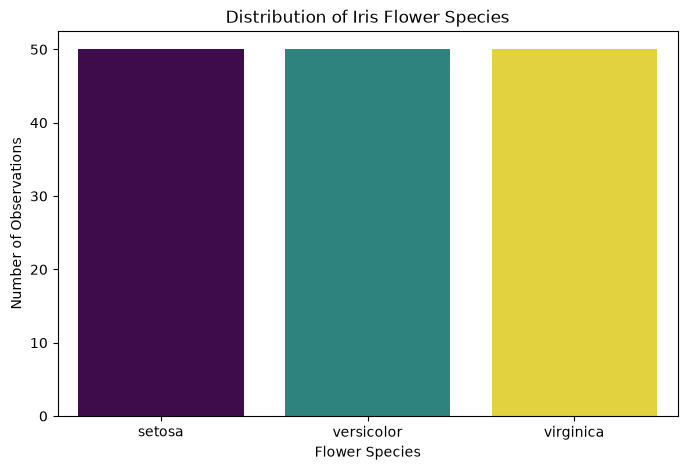

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="viridis",
    legend=False
)

plt.xticks(
    ticks=[0, 1, 2],
    labels=iris.target_names
)

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Observations")

plt.show()

In [10]:
# Remove duplicate records
df = df.drop_duplicates()

# Check the new dataset shape
print("Dataset shape after removing duplicates:")
print(df.shape)

# Confirm that there are no duplicates
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates:
(149, 5)
Remaining duplicates: 0


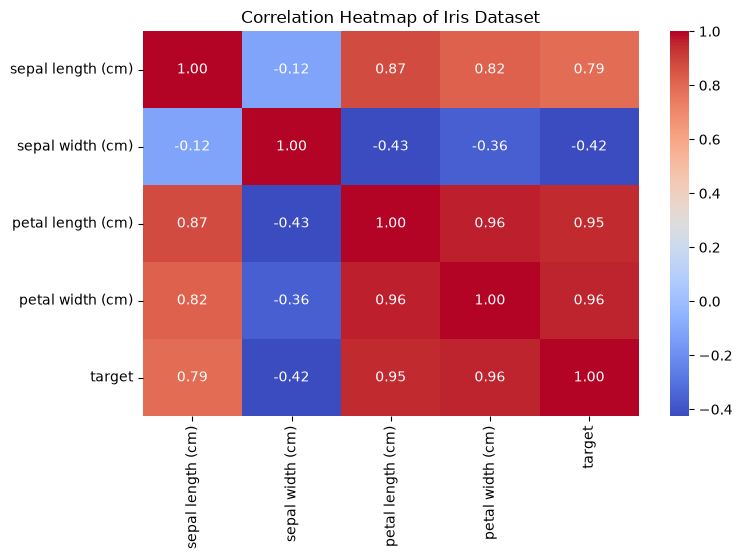

In [11]:
# Calculate correlation between numerical features
correlation = df.corr(numeric_only=True)

# Display correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Iris Dataset")
plt.show()

4. Feature Selection and Target Separation

In this stage, the dataset is divided into features (X) 
and the target variable (y). The features contain the 
measurements of the Iris flowers, while the target 
contains the species to be predicted.

In [12]:
# Separate features and target variable

X = df.drop("target", axis=1)
y = df["target"]

# Display the shapes of X and y

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (149, 4)
Target Shape: (149,)


# 5. Splitting the Dataset

The dataset is divided into training and testing sets.
80% of the data is used to train the model, while 
20% is reserved for testing its performance.

In [13]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (119, 4)
Testing Features: (30, 4)
Training Target: (119,)
Testing Target: (30,)


# 6. Model Training Using Logistic Regression

In this stage, Logistic Regression is used to train a 
classification model that can identify the species of 
Iris flowers based on their measurements.

In [14]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create the model

model = LogisticRegression(max_iter=200)

# Train the model

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


# 7. Making Predictions

After training the model, we use the testing dataset to make predictions. This helps us determine how well the model can identify flower species from measurements it has not seen before.

In [15]:
# Make predictions using the testing data

y_pred = model.predict(X_test)

# Display actual and predicted values

print("Actual Values:", y_test.values)
print("Predicted Values:", y_pred)

Actual Values: [1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 1 0 2 0 1 2 0 0 1 1 2 2 2 1]
Predicted Values: [1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 2 0 0 1 1 2 2 2 1]


# 8. Model Evaluation Using Accuracy Score

Accuracy measures the percentage of predictions made correctly by the machine-learning model.

In [16]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9666666666666667
Accuracy Percentage: 96.66666666666667 %


# 9. Confusion Matrix

A confusion matrix is used to evaluate the performance of a classification model. It compares the actual flower species with the species predicted by the model.

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


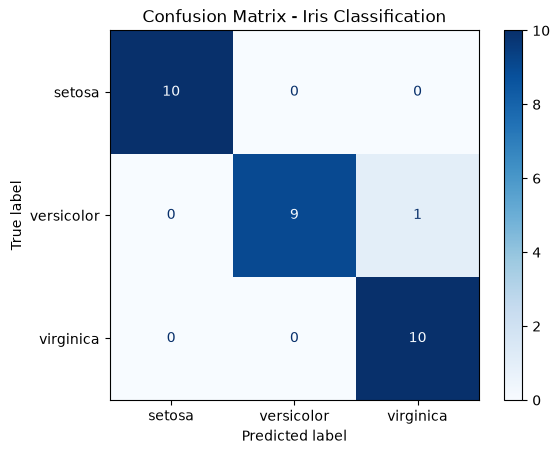

In [17]:
# Import evaluation tools

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define the flower species names

class_names = ['setosa', 'versicolor', 'virginica']

# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Confusion Matrix - Iris Classification")
plt.show()

## 10. Classification Report

The classification report provides a detailed evaluation of the model using precision, recall, F1-score and support.

In [18]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Model Evaluation and Interpretation

The model achieved an accuracy of 96.67%, indicating that it performed very well in classifying the Iris flower species. The classification report shows strong precision, recall and F1-scores across all three species. The confusion matrix also shows that only one flower was incorrectly classified.